<a href="https://colab.research.google.com/github/ThomasAko/physics-constraints-qm7-qm9/blob/main/Physics_Constraints_QM7_to_QM9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Physics constraints for molecular machine learning on QM7

**Thomas Ako**

**Can building physics into a neural network's loss make it learn better?** This notebook tests that question on QM7: 7,165 small organic molecules with DFT atomization energies, represented by their Coulomb matrices. Along the way it became a study of how to tell whether a result can be trusted.

**A note on the data.** An earlier version of this study loaded QM7 through DeepChem's `load_qm7`. A sanity check showed that its features and labels did not match: atom counts explained only 19% of the variance in atomization energy, a quantity they should almost fully determine, and some molecules contained only hydrogen. Every model stalled near 60% accuracy as a result. This notebook loads the original `qm7.mat` instead. The diagnosis is kept in a companion notebook, [QM7_DeepChem_Diagnosis.ipynb](https://github.com/ThomasAko/physics-constraints-qm7-qm9/blob/main/QM7_DeepChem_Diagnosis.ipynb).

The story in brief:

1. **Data check (1.1).** On the original file, atom counts predict atomization energy with R² = 0.992, the check the DeepChem data failed.
2. **Classification revisited (1.2).** The same models as the earlier study jump from about 60% to 97–98% accuracy. The task becomes too easy to tell models apart, so the study moves to regression.
3. **Regression baselines (1.3).** Two training settings carried over from classification broke the network; fixing them and sorting the Coulomb matrices brings it below the atom-count baseline.
4. **Physics term (1.4–1.5).** A virial-theorem penalty, 2⟨T⟩ + ⟨V⟩ = 0, on two auxiliary heads gives no measurable gain, and the penalty can be satisfied without learning any physics.
5. **Conclusions and outlook (1.6).**

Runtime: about 30 minutes on a Colab T4 GPU. Random forests and data splits are fully seeded; neural-network results vary by about 1 kcal/mol between GPU runs, so the saved outputs are the reference run that the text describes.

In [1]:
!pip install -q rdkit keras-tuner


In [2]:
import os, json, time, random, math
import urllib.request, scipy.io
from types import SimpleNamespace
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

import tensorflow as tf
# Let TensorFlow allocate GPU memory as needed instead of reserving all of it
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
from tensorflow.keras import layers, models

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.stats import ttest_ind

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); random.seed(SEED)

# Part 1: QM7 atomization energy from Coulomb matrices

## 1.1 Data

QM7 contains 7,165 small organic molecules (up to 23 atoms, at most 7 of them C, N, O or S) with DFT atomization energies. Each molecule is represented by its **Coulomb matrix**:

$$C_{ij} = \begin{cases} 0.5\,Z_i^{2.4} & i = j \\ \dfrac{Z_i Z_j}{\lvert R_i - R_j \rvert} & i \neq j \end{cases}$$

The diagonal encodes each atom's identity; the off-diagonal entries are the nuclear repulsion between atom pairs. Molecules with fewer than 23 atoms are padded with zeros. I flatten each 23 × 23 matrix into 529 features and standardize them, so the large diagonal values do not drown out the smaller interaction terms. Part 1 uses the data in two ways: first as a classification task (Section 1.2), to compare directly with the earlier version of this study, then as a regression task (Section 1.3), the main study.

**Source.** I load the original `qm7.mat` file from quantum-machine.org, which stores the Coulomb matrices (`X`) and atomization energies in kcal/mol (`T`) for all 7,165 molecules, already paired. I do not use DeepChem's `load_qm7`: it rebuilds the dataset by parsing structure files with RDKit, and in an earlier version of this study its features and labels turned out not to match (see the note at the top).

**Split.** The molecules are split at random into training (80%, 5,731), validation (10%, 717) and test (10%, 717) sets. Because the split is random rather than by chemical scaffold, the test set contains the same kinds of molecules as the training set. This is an interpolation test, not a test of generalization to new chemistry.

**Sanity check.** Atomization energy is close to *extensive*: it is roughly a sum of contributions from each atom and bond. Before training anything, the cell after the loader recovers each molecule's atom counts from the Coulomb-matrix diagonal and checks that they predict the energy well. This is the check the DeepChem data failed.

In [3]:
urllib.request.urlretrieve("http://quantum-machine.org/data/qm7.mat", "qm7.mat")
d = scipy.io.loadmat("qm7.mat")
X_all = d["X"].reshape(len(d["X"]), -1)        # 7,165 Coulomb matrices, flattened to 529 features
y_all = d["T"].ravel()                          # atomization energies, kcal/mol

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(y_all))
n_hold = 717                                     # 10% each for validation and test
te, va, tr = idx[:n_hold], idx[n_hold:2 * n_hold], idx[2 * n_hold:]

train_dataset, valid_dataset, test_dataset = (
    SimpleNamespace(X=X_all[i], y=y_all[i].reshape(-1, 1)) for i in (tr, va, te))
print(f"train / valid / test: {len(tr)} / {len(va)} / {len(te)} of {len(y_all)} molecules")

train / valid / test: 5731 / 717 / 717 of 7165 molecules


In [4]:
def atom_counts(ds):
    """Recover atom counts from the Coulomb-matrix diagonal, C_ii = 0.5 Z^2.4."""
    C = ds.X.reshape(len(ds.X), 23, 23)
    Z = np.rint((2 * np.clip(np.diagonal(C, axis1=1, axis2=2), 0, None)) ** (1/2.4)).astype(int)
    feats = {f"n_{s}": (Z == z).sum(1) for s, z in [("H", 1), ("C", 6), ("N", 7), ("O", 8), ("S", 16)]}
    feats["n_atoms"] = (Z > 0).sum(1)
    return pd.DataFrame(feats)

A_train, A_test = atom_counts(train_dataset), atom_counts(test_dataset)
y_cont = train_dataset.y.ravel()
heavy = A_train[["n_C", "n_N", "n_O", "n_S"]].sum(1)

print(A_train.describe().loc[["mean", "min", "max"]].round(2))
print("\nenergy range (kcal/mol):", y_cont.min().round(1), "to", y_cont.max().round(1))
print("corr(n_atoms, energy):", round(np.corrcoef(A_train.n_atoms, y_cont)[0, 1], 3))
print("R² of linear model on counts:", round(LinearRegression().fit(A_train, y_cont).score(A_train, y_cont), 3))
print("molecules with no heavy atom:", int((heavy == 0).sum()))

        n_H  n_C   n_N   n_O   n_S  n_atoms
mean   8.64  5.0  0.93  0.83  0.04    15.43
min    0.00  1.0  0.00  0.00  0.00     4.00
max   16.00  7.0  3.00  3.00  1.00    23.00

energy range (kcal/mol): -2192.0 to -404.9
corr(n_atoms, energy): -0.971
R² of linear model on counts: 0.992
molecules with no heavy atom: 0


In [5]:
# Inputs: standardize using training-set statistics only
scaler_X = StandardScaler().fit(train_dataset.X)
X_train_scaled, X_val_scaled, X_test_scaled = (
    scaler_X.transform(ds.X) for ds in (train_dataset, valid_dataset, test_dataset))

# Raw energies in kcal/mol
y_train_raw, y_val_raw, y_test_raw = (ds.y.ravel() for ds in (train_dataset, valid_dataset, test_dataset))

# Classification target (Section 1.2): high energy = above the training-set median
median_energy = np.median(y_train_raw)
encoder = OneHotEncoder(sparse_output=False).fit([["High_Energy"], ["Low_Energy"]])
def one_hot(y):
    return encoder.transform(np.where(y > median_energy, "High_Energy", "Low_Energy").reshape(-1, 1))
y_train_cls, y_val_cls, y_test_cls = one_hot(y_train_raw), one_hot(y_val_raw), one_hot(y_test_raw)

# Regression target (Section 1.3): energies standardized with training-set statistics
y_mean, y_std = y_train_raw.mean(), y_train_raw.std()
y_train_reg, y_val_reg, y_test_reg = ((y - y_mean) / y_std for y in (y_train_raw, y_val_raw, y_test_raw))

print(f"median training energy: {median_energy:.1f} kcal/mol")
print(f"training energies: mean {y_mean:.1f}, std {y_std:.1f} kcal/mol")
print(f"share labelled High_Energy: train {y_train_cls[:, 0].mean():.2f}, test {y_test_cls[:, 0].mean():.2f}")

median training energy: -1544.2 kcal/mol
training energies: mean -1537.8, std 225.2 kcal/mol
share labelled High_Energy: train 0.50, test 0.50


**Targets.** Two targets are built from the same energies, using training-set statistics only so that no test information leaks into the preprocessing:

* **Classification (Section 1.2):** a molecule is labelled High_Energy if its atomization energy is above the training set median, otherwise Low_Energy. This is the same rule used in the earlier version of this study.
* **Regression (Section 1.3):** the atomization energy itself, standardized with the training-set mean (−1,537.8 kcal/mol) and standard deviation (225.2 kcal/mol) for training. Every prediction is converted back to kcal/mol before scoring.

Atomization energies are negative, so "high" means closer to zero, which in practice means smaller molecules.

In [6]:
for name, a, yc, yr in [("train", X_train_scaled, y_train_cls, y_train_reg),
                        ("valid", X_val_scaled, y_val_cls, y_val_reg),
                        ("test", X_test_scaled, y_test_cls, y_test_reg)]:
    print(f"{name:6s} X {a.shape}   classification y {yc.shape}   regression y {yr.shape}")

train  X (5731, 529)   classification y (5731, 2)   regression y (5731,)
valid  X (717, 529)   classification y (717, 2)   regression y (717,)
test   X (717, 529)   classification y (717, 2)   regression y (717,)


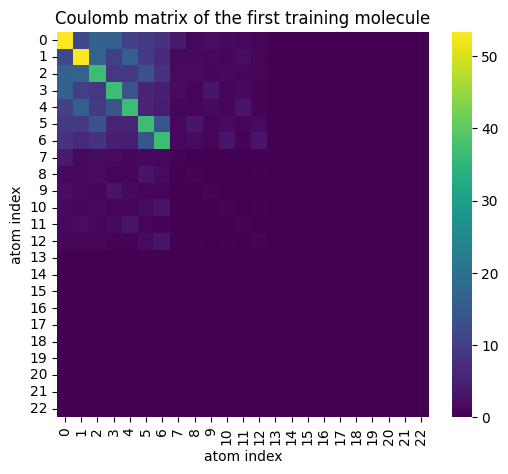

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(train_dataset.X[0].reshape(23, 23), cmap="viridis")
plt.title("Coulomb matrix of the first training molecule"); plt.xlabel("atom index"); plt.ylabel("atom index")
plt.show()



## 1.2 Classification revisited

The earlier version of this study classified molecules as high or low energy on the DeepChem data, and every model stalled near 60% accuracy. This section reruns the same models with the same settings on the original file. Only the data change, so any difference in the results is due to the data.

**Models**

1. **Random forest (100 trees).** A non-parametric reference. It assumes no functional form and needs no gradient training, so it shows whether a neural network earns its extra complexity. It has no fixed parameter count; its size grows with the data. A fully grown tree on $n = 5{,}731$ training molecules has at most $2n - 1 = 11{,}461$ nodes, so 100 trees hold at most about 1.15 million. The actual count is printed below.
2. **Funnel network:** 529 → 256 → 128 → 64 → 32 → 2, ReLU, dropout 0.2 after the first three hidden layers. It compresses the Coulomb matrix step by step into a few features that separate the two classes.
3. **Tuned network:** 529 → 64 → 416 → 224 → 256 → 128 → 2, dropout only after the 256-unit layer. This architecture came from a Keras-Tuner Hyperband search in the earlier study: 412 trials in about two hours (7,200 s ÷ 412 ≈ 17 s per trial). Hyperband trains many candidates briefly, drops the weak ones early, and gives the promising ones more epochs; the search chose depth, width, and where to place dropout. The 64-unit first layer is a bottleneck that forces a compact summary of the input before the wider layers work on it. I keep the architecture fixed here so the comparison isolates the data. Set `RUN_TUNER = True` to search again on the corrected data.
4. **Logistic regression and random forest on atom counts:** composition only, no geometry. In the earlier study these exposed the data problem; here they show how much of the task composition alone solves.

All networks train for 100 epochs, as in the earlier study.

### Parameter counts

A dense layer from $n_\text{in}$ to $n_\text{out}$ units has $n_\text{in} \times n_\text{out}$ weights plus $n_\text{out}$ biases. Dropout and softmax add none.

| Funnel layer | Weights | Biases | Parameters |
|---|---|---|---|
| 529 → 256 | 529 × 256 = 135,424 | 256 | 135,680 |
| 256 → 128 | 256 × 128 = 32,768 | 128 | 32,896 |
| 128 → 64 | 128 × 64 = 8,192 | 64 | 8,256 |
| 64 → 32 | 64 × 32 = 2,048 | 32 | 2,080 |
| 32 → 2 | 32 × 2 = 64 | 2 | 66 |
| **Total** | | | **178,978** |

| Tuned layer | Weights | Biases | Parameters |
|---|---|---|---|
| 529 → 64 | 529 × 64 = 33,856 | 64 | 33,920 |
| 64 → 416 | 64 × 416 = 26,624 | 416 | 27,040 |
| 416 → 224 | 416 × 224 = 93,184 | 224 | 93,408 |
| 224 → 256 | 224 × 256 = 57,344 | 256 | 57,600 |
| 256 → 128 | 256 × 128 = 32,768 | 128 | 32,896 |
| 128 → 2 | 128 × 2 = 256 | 2 | 258 |
| **Total** | | | **245,122** |

In the funnel, 76% of the parameters (135,680 of 178,978) sit in the first layer. The diamond's bottleneck shrinks that layer to 33,920 and moves most of its capacity into the 416 → 224 layer.

### How precisely can 717 molecules rank these models?

Each of the $n = 717$ test molecules is classified either correctly or not, so the measured accuracy $\hat p$ is a binomial proportion with standard error

$$\text{SE} = \sqrt{\frac{\hat p\,(1-\hat p)}{n}}.$$

The uncertainty depends on the accuracy itself:

| $\hat p$ | $\hat p(1-\hat p)$ | Variance: ÷ 717 | SE: √ variance | 95% half-width: 1.96 × SE |
|---|---|---|---|---|
| 0.60 | 0.60 × 0.40 = 0.24 | 0.000335 | 0.0183 = 1.8 percentage points | 1.96 × 0.0183 = 0.0359 = 3.6 percentage points |
| 0.95 | 0.95 × 0.05 = 0.0475 | 0.0000662 | 0.00814 = 0.8 percentage points | 1.96 × 0.00814 = 0.0160 = 1.6 percentage points |

The table below reports this 95% half-width for each model. Comparing two models needs the uncertainty of their *difference*. If the two accuracies were independent, that SE would be $\sqrt{2}$ times larger, so a gap of about $1.96 \times \sqrt{2} \times \text{SE}$ would be needed at 95%. Both models are scored on the same molecules, so their errors are correlated, and a paired test (McNemar's, on the molecules where they disagree) is the sharper tool.

In [8]:
y_train, y_val, y_test = y_train_cls, y_val_cls, y_test_cls
y_true = np.argmax(y_test, axis=1)          # column 0 = High_Energy

In [9]:
RUN_TUNER = False      # True searches again on the corrected data (about two hours)

HP_TUNED = {"num_layers": 5,
            "units_0": 64,  "dropout_0": False, "units_1": 416, "dropout_1": False,
            "units_2": 224, "dropout_2": False, "units_3": 256, "dropout_3": True,
            "units_4": 128, "dropout_4": False}
HP_FUNNEL = {"num_layers": 4,
             "units_0": 256, "dropout_0": True, "units_1": 128, "dropout_1": True,
             "units_2": 64,  "dropout_2": True, "units_3": 32,  "dropout_3": False}

if RUN_TUNER:
    import keras_tuner as kt
    def model_builder_general(hp):
        m = tf.keras.Sequential([tf.keras.layers.Input(shape=(529,))])
        for i in range(hp.Int("num_layers", 1, 8)):
            m.add(tf.keras.layers.Dense(hp.Int(f"units_{i}", 32, 512, step=32), activation="relu"))
            if hp.Boolean(f"dropout_{i}"): m.add(tf.keras.layers.Dropout(0.2))
        m.add(tf.keras.layers.Dense(2, activation="softmax"))
        m.compile("adam", "categorical_crossentropy", metrics=["accuracy"])
        return m
    tuner = kt.Hyperband(model_builder_general, objective="val_accuracy", max_epochs=100, factor=2,
                         hyperband_iterations=10, directory="tuner", project_name="qm7_layers")
    tuner.search(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val))
    best = tuner.get_best_hyperparameters(1)[0]
    HP_TUNED = {k: best.get(k) for k in best.values}

In [10]:
def dense_net(hp):
    m = models.Sequential([layers.Input(shape=(529,))])
    for i in range(hp["num_layers"]):
        m.add(layers.Dense(hp[f"units_{i}"], activation="relu"))
        if hp[f"dropout_{i}"]: m.add(layers.Dropout(0.2))
    m.add(layers.Dense(2, activation="softmax"))
    m.compile("adam", "categorical_crossentropy", metrics=["accuracy"])
    return m

def scores(y_pred):
    return dict(Accuracy=accuracy_score(y_true, y_pred),
                **{"Precision (High)": precision_score(y_true, y_pred, pos_label=0),
                   "Recall (High)": recall_score(y_true, y_pred, pos_label=0),
                   "F1": f1_score(y_true, y_pred, pos_label=0)})

In [11]:
EPOCHS = 100           # same settings as the earlier study, so only the data differ
results = {}

rf_model = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_train_scaled, np.argmax(y_train, 1))
print("random forest, total tree nodes:", sum(est.tree_.node_count for est in rf_model.estimators_))
results["Random forest"] = scores(rf_model.predict(X_test_scaled))

model_tuned = dense_net(HP_TUNED)
hist_tuned = model_tuned.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32,
                             validation_data=(X_val_scaled, y_val), verbose=0)
results["NN, tuned"] = scores(np.argmax(model_tuned.predict(X_test_scaled, verbose=0), 1))

# ensure reproducibility
tf.keras.utils.set_random_seed(SEED)

model_funnel = dense_net(HP_FUNNEL)
hist_funnel = model_funnel.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32,
                               validation_data=(X_val_scaled, y_val), verbose=0)
results["NN, funnel"] = scores(np.argmax(model_funnel.predict(X_test_scaled, verbose=0), 1))

for name, clf in [("Logistic regression, atom counts", LogisticRegression(max_iter=2000)),
                  ("Random forest, atom counts", RandomForestClassifier(200, random_state=SEED))]:
    clf.fit(A_train, np.argmax(y_train, 1))
    results[name] = scores(clf.predict(A_test))

res_cls = pd.DataFrame(results).T
res_cls["± 95% (points)"] = 100 * 1.96 * np.sqrt(res_cls.Accuracy * (1 - res_cls.Accuracy) / len(y_true))
res_cls["Accuracy, DeepChem data"] = pd.Series({
    "Random forest": 0.6316, "NN, tuned": 0.6053, "NN, funnel": 0.6213,
    "Logistic regression, atom counts": 0.6316, "Random forest, atom counts": 0.6550})
res_cls.round(4)

random forest, total tree nodes: 24642


,Accuracy,Precision (High),Recall (High),F1,± 95% (points),"Accuracy, DeepChem data"
Random forest,0.9777,0.9832,0.9724,0.9778,1.0812,0.6316
"NN, tuned",0.9707,0.9749,0.9669,0.9709,1.2342,0.6053
"NN, funnel",0.9693,0.9722,0.9669,0.9695,1.2624,0.6213
"Logistic regression, atom counts",0.9735,0.9725,0.9751,0.9738,1.1757,0.6316
"Random forest, atom counts",0.9735,0.9725,0.9751,0.9738,1.1757,0.6550


**Reading the results.** With the original data, every model jumps from about 60% to 97–98% accuracy. The models and settings are identical to the earlier study, so the data alone account for the change. Composition solves almost the whole task: both atom-count models reach 97.4%, and they make identical predictions. The best Coulomb-matrix model, the random forest, makes 16 errors on 717 test molecules against 19 for the atom-count models, a difference of 0.4 points, well within the ±1.1-point uncertainty. The two networks do slightly worse than atom counts. Every difference in the table is within noise.

In [12]:
preds = {
    "Random forest": rf_model.predict(X_test_scaled),
    "NN, tuned": np.argmax(model_tuned.predict(X_test_scaled, verbose=0), 1),
    "NN, funnel": np.argmax(model_funnel.predict(X_test_scaled, verbose=0), 1),
    "Logistic regression, atom counts":
        LogisticRegression(max_iter=2000).fit(A_train, np.argmax(y_train, 1)).predict(A_test),
    "Random forest, atom counts":
        RandomForestClassifier(200, random_state=SEED).fit(A_train, np.argmax(y_train, 1)).predict(A_test),
}

rows = []
for name, y_pred in preds.items():
    # labels=[1, 0] puts low (1) first and high (0) second, so .ravel() gives tn, fp, fn, tp with high as positive
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[1, 0]).ravel()
    rows.append({"Model": name, "TP": tp, "FN": fn, "FP": fp, "TN": tn, "Predicted high": tp + fp})

pd.DataFrame(rows).set_index("Model")

,TP,FN,FP,TN,Predicted high
Model,,,,,
Random forest,352,10,6,349,358
"NN, tuned",350,12,9,346,359
"NN, funnel",350,12,10,345,360
"Logistic regression, atom counts",353,9,10,345,363
"Random forest, atom counts",353,9,10,345,363


The test set holds 362 high-energy and 355 low-energy molecules. The errors are few, 16 to 22 per model, and every model misses about as many high molecules as it falsely flags, so none leans toward one class. The next cell checks where the errors fall.

In [13]:
d = np.abs(y_test_raw - median_energy)                          # distance of each test energy from the threshold
wrong = preds["Logistic regression, atom counts"] != y_true
print(f"median distance from threshold, all test molecules:   {np.median(d):.1f} kcal/mol")
print(f"median distance from threshold, misclassified ones:   {np.median(d[wrong]):.1f} kcal/mol")

median distance from threshold, all test molecules:   162.2 kcal/mol
median distance from threshold, misclassified ones:   5.8 kcal/mol


**Where the errors fall.** The misclassified molecules lie a median of 5.8 kcal/mol from the threshold, compared with 162.2 kcal/mol for the test set as a whole, about 28 times closer. For scale, 5.8 kcal/mol is under 3% of the 225 kcal/mol spread of the energies. The remaining errors are borderline cases, where a small error in the implied energy flips the label, not failures of the model.

**Why move to regression.** At 97–98% accuracy, with every difference inside the noise, classification can no longer tell models apart, and a physics term would have nothing measurable to improve. The few remaining errors sit near the threshold, where the binary label throws away the information that matters: how close the energy is to the cut. Regression keeps that information. Every kcal/mol of error counts, so a model that uses geometry beyond composition has room to show it. The rest of Part 1 therefore predicts the energy itself.

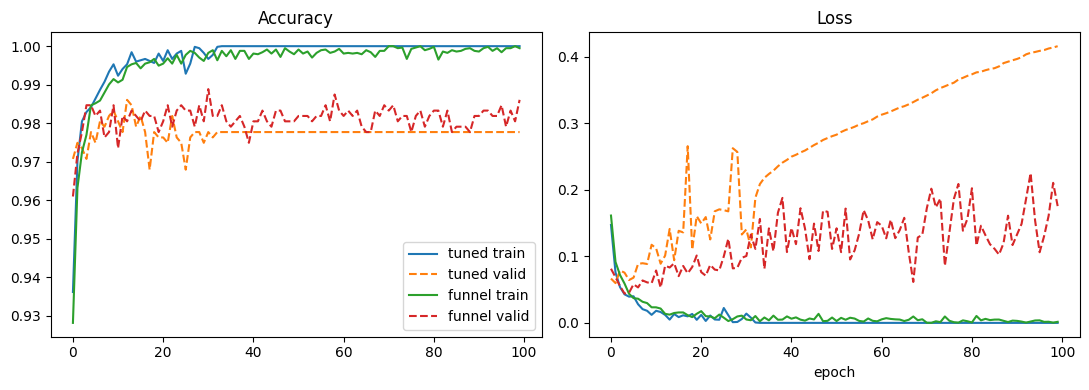

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for h, name in [(hist_tuned, "tuned"), (hist_funnel, "funnel")]:
    ax[0].plot(h.history["accuracy"], label=f"{name} train"); ax[0].plot(h.history["val_accuracy"], "--", label=f"{name} valid")
    ax[1].plot(h.history["loss"], label=f"{name} train");     ax[1].plot(h.history["val_loss"], "--", label=f"{name} valid")
ax[0].set_title("Accuracy"); ax[1].set_title("Loss"); ax[0].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**Training curves.** Both networks learn the task almost immediately: validation accuracy reaches about 97–98% within the first few epochs, and further training adds nothing. They then overfit. Training accuracy approaches 100% while validation accuracy stops improving, and validation loss rises, so the networks grow more confident on the same predictions, including the ones they get wrong, and cross-entropy penalizes each confident mistake more heavily. The tuned network, with more parameters and only one dropout layer, overfits further. Validation loss is lowest within the first few epochs, so a hundred epochs is far more than the task needs. The regression networks in Section 1.3 therefore use early stopping: training ends when the validation loss stops improving, and the best weights are restored.

## 1.3 Regression baselines

The rest of Part 1 predicts the energy itself. Each model below uses data alone, with no physics term. Errors are reported in kcal/mol on the 717 test molecules, as the mean absolute error (MAE, the standard QM7 metric), the root-mean-square error (RMSE), and R².

**Models**

1. **Mean predictor:** always predicts the training-set mean, −1,537.8 kcal/mol. Its error equals the spread of the energies, so every useful model must do far better.
2. **Linear model on atom counts:** the energy as a weighted sum of the numbers of H, C, N, O and S atoms. It uses composition only, no geometry. Section 1.1 showed that it already explains 99.2% of the variance. With a spread of 225.2 kcal/mol, that implies an RMSE of about $225.2 \times \sqrt{1 - 0.992} \approx 20$ kcal/mol. **This is the bar to beat:** a Coulomb-matrix model is only worth having if it adds something beyond composition.
3. **Random forest on atom counts** (100 trees): the same information, with nonlinear combinations allowed.
4. **Random forest on the Coulomb matrix** (100 trees): a non-parametric model that sees the geometry.
5. **Funnel network on the Coulomb matrix:** 529 → 256 → 128 → 64 → 32 → 1, ReLU, dropout 0.2 after the first three hidden layers, with a linear output.

The tuned architecture from Section 1.2 is not used here. It was found by a search for classification on the earlier data, so it has no special claim for regression.

**Early stopping.** Section 1.2 showed the classification networks reaching their best validation loss within a few epochs and then overfitting. The regression network therefore trains with early stopping: training ends once the validation loss has not improved for 30 epochs, and the best weights are restored. The upper limit of 1,000 epochs is never reached in practice.

### Parameter count of the funnel network

A dense layer from $n_\text{in}$ to $n_\text{out}$ units has $n_\text{in} \times n_\text{out}$ weights plus $n_\text{out}$ biases. Dropout adds none.

| Layer | Weights | Biases | Parameters |
|---|---|---|---|
| 529 → 256 | 529 × 256 = 135,424 | 256 | 135,680 |
| 256 → 128 | 256 × 128 = 32,768 | 128 | 32,896 |
| 128 → 64 | 128 × 64 = 8,192 | 64 | 8,256 |
| 64 → 32 | 64 × 32 = 2,048 | 32 | 2,080 |
| 32 → 1 | 32 × 1 = 32 | 1 | 33 |
| **Total** | | | **178,945** |

The only change from the classification funnel is the output layer: one linear unit instead of two softmax units, which removes 33 parameters (178,978 − 33 = 178,945). With 5,731 training molecules, that is about 31 parameters per molecule (178,945 ÷ 5,731 ≈ 31.2), so overfitting is a real risk without early stopping.

In [15]:
y_train, y_val, y_test = y_train_reg, y_val_reg, y_test_reg
y_true = y_test_raw                          # test energies in kcal/mol

In [16]:
def dense_net_reg(hp):
    m = models.Sequential([layers.Input(shape=(529,))])
    for i in range(hp["num_layers"]):
        m.add(layers.Dense(hp[f"units_{i}"], activation="relu"))
        if hp[f"dropout_{i}"]: m.add(layers.Dropout(0.2))
    m.add(layers.Dense(1))                                  # linear output: standardized energy
    m.compile("adam", "mse")
    return m

def early_stop(monitor="val_loss"):
    return tf.keras.callbacks.EarlyStopping(monitor=monitor, patience=30, restore_best_weights=True)

def scores_reg(y_pred_std):
    """Convert standardized predictions back to kcal/mol and score them on the test set."""
    err = np.ravel(y_pred_std) * y_std + y_mean - y_true
    return {"MAE (kcal/mol)": np.abs(err).mean(),
            "RMSE (kcal/mol)": np.sqrt((err ** 2).mean()),
            "R²": 1 - (err ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()}

In [17]:
EPOCHS = 1000          # upper limit; early stopping ends training well before this
results = {}

results["Mean predictor"] = scores_reg(np.zeros(len(y_true)))
results["Linear, atom counts"] = scores_reg(LinearRegression().fit(A_train, y_train).predict(A_test))
results["Random forest, atom counts"] = scores_reg(
    RandomForestRegressor(100, random_state=SEED, n_jobs=-1).fit(A_train, y_train).predict(A_test))

rf_reg = RandomForestRegressor(100, random_state=SEED, n_jobs=-1).fit(X_train_scaled, y_train)
results["Random forest, Coulomb"] = scores_reg(rf_reg.predict(X_test_scaled))

# ensure reproducibility
tf.keras.utils.set_random_seed(SEED)

funnel_reg = dense_net_reg(HP_FUNNEL)
hist_funnel_reg = funnel_reg.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32,
                                 validation_data=(X_val_scaled, y_val), callbacks=[early_stop()], verbose=0)
print(f"funnel stopped after {len(hist_funnel_reg.history['loss'])} epochs")
results["NN funnel, Coulomb"] = scores_reg(funnel_reg.predict(X_test_scaled, verbose=0))

pd.DataFrame(results).T.round(3)

funnel stopped after 161 epochs


,MAE (kcal/mol),RMSE (kcal/mol),R²
Mean predictor,180.624,222.548,-0.000
"Linear, atom counts",16.309,21.111,0.991
"Random forest, atom counts",15.324,20.701,0.991
"Random forest, Coulomb",11.875,18.345,0.993
"NN funnel, Coulomb",21.482,29.322,0.983


**Reading the baselines.** The mean predictor's error (RMSE 222.5 kcal/mol) is the spread of the test energies. The linear model on atom counts reaches an RMSE of 21.1 kcal/mol (MAE 16.3), close to the value of about 20 implied by R² = 0.991, and a random forest on the same counts barely improves on it, so composition acts almost linearly. Geometry helps: the random forest on the Coulomb matrix lowers the MAE to 11.9 kcal/mol, 27% below the atom count model. The funnel network, by contrast, has an MAE of 21.5 kcal/mol, worse than the five-coefficient linear model.

best epoch: 131 | best val MSE (standardized): 0.0153
largest |standardized input| in training set: 57.2
largest |standardized input| in test set:     22.6


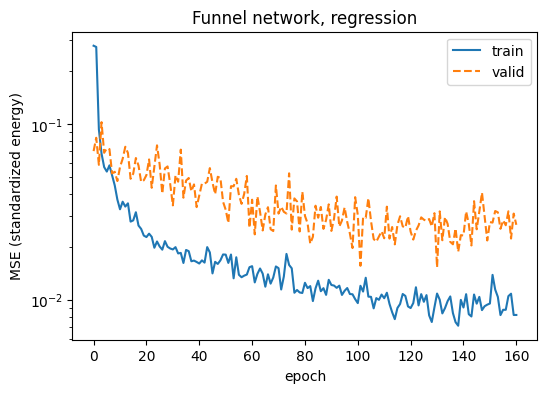

In [18]:
vl = hist_funnel_reg.history["val_loss"]
print("best epoch:", int(np.argmin(vl)) + 1, "| best val MSE (standardized):", round(min(vl), 4))
print("largest |standardized input| in training set:", np.abs(X_train_scaled).max().round(1))
print("largest |standardized input| in test set:    ", np.abs(X_test_scaled).max().round(1))

plt.figure(figsize=(6, 4))
plt.plot(hist_funnel_reg.history["loss"], label="train"); plt.plot(vl, "--", label="valid")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardized energy)"); plt.legend()
plt.title("Funnel network, regression"); plt.show()

**Problem.** The funnel network has an MAE of 21.5 kcal/mol, worse than a linear model on five atom counts (16.3). Its best validation MSE, 0.0153 in standardized units, corresponds to an RMSE of $\sqrt{0.0153} \times 225.2 \approx 28$ kcal/mol, consistent with the test RMSE of 29.3, so this is not an unlucky test set. Across earlier runs this network landed anywhere between 20 and 33 kcal/mol, always worse than the linear model.

### Why the network falls short, and a fix

**Problem.** The funnel network has an MAE of 21.5 kcal/mol, worse than a linear model on five atom counts (16.3). This is not an unlucky test set: the network's best validation error is similar. It trains on standardized energies (one unit = 225.2 kcal/mol, the training-set standard deviation), and its best validation MSE of 0.0153 corresponds to an RMSE of $\sqrt{0.0153} \times 225.2 \approx 28$ kcal/mol, close to the test RMSE of 29.3. Across earlier runs this network landed anywhere between 20 and 33 kcal/mol, always worse than the linear model.

**Diagnosis.** Two settings carried over from classification are the likely cause. Adam's default learning rate takes steps too coarse for errors of a few kcal/mol (about 0.01 in standardized units), so the weights bounce around a good solution without settling. Dropout adds random noise directly to the predicted value: harmless when only the sign of a decision matters, damaging when every kcal/mol counts.

**Test.** Retrain the same architecture with no dropout and a learning rate that halves whenever the validation loss stalls for 10 epochs, with patience raised to 50. If the MAE falls below the 16.3 kcal/mol of the atom-count model, training settings were the problem.

In [19]:
# Regression version of the funnel: same layers, no dropout
HP_FUNNEL_REG = {**HP_FUNNEL, **{f"dropout_{i}": False for i in range(HP_FUNNEL["num_layers"])}}

def callbacks_reg(monitor="val_loss"):
    return [tf.keras.callbacks.ReduceLROnPlateau(monitor=monitor, mode="min", factor=0.5, patience=10, min_lr=1e-6),
            tf.keras.callbacks.EarlyStopping(monitor=monitor, mode="min", patience=50, restore_best_weights=True)]

# ensure reproducibility
tf.keras.utils.set_random_seed(SEED)

funnel_reg2 = dense_net_reg(HP_FUNNEL_REG)
hist_funnel_reg2 = funnel_reg2.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32,
                                   validation_data=(X_val_scaled, y_val), callbacks=callbacks_reg(), verbose=0)
vl2 = hist_funnel_reg2.history["val_loss"]
print(f"stopped after {len(vl2)} epochs, best epoch {int(np.argmin(vl2)) + 1}")
results["NN funnel, Coulomb (no dropout, LR schedule)"] = scores_reg(funnel_reg2.predict(X_test_scaled, verbose=0))

pd.DataFrame(results).T.round(3)

stopped after 127 epochs, best epoch 77


,MAE (kcal/mol),RMSE (kcal/mol),R²
Mean predictor,180.624,222.548,-0.000
"Linear, atom counts",16.309,21.111,0.991
"Random forest, atom counts",15.324,20.701,0.991
"Random forest, Coulomb",11.875,18.345,0.993
"NN funnel, Coulomb",21.482,29.322,0.983
"NN funnel, Coulomb (no dropout, LR schedule)",15.230,19.719,0.992


**Result of the fix.** Without dropout and with a learning rate schedule, the network trains for 127 epochs (best at epoch 77) and its MAE falls from 21.5 to 15.2 kcal/mol. That roughly matches the atom count models (15.3–16.3) but trails the random forest on the Coulomb matrix (11.9), so it is still not extracting the geometric information the random forest uses. The next cell tests one likely reason: atom ordering.

In [20]:
def sort_coulomb(X):
    """Reorder each matrix's rows and columns by descending row norm (Rupp et al., 2012)."""
    C = X.reshape(len(X), 23, 23)
    order = np.argsort(-np.linalg.norm(C, axis=2), axis=1)      # padding rows (norm 0) go last
    return np.stack([c[o][:, o] for c, o in zip(C, order)]).reshape(len(X), -1)

scaler_sorted = StandardScaler().fit(sort_coulomb(train_dataset.X))
Xs_train, Xs_val, Xs_test = (scaler_sorted.transform(sort_coulomb(ds.X))
                             for ds in (train_dataset, valid_dataset, test_dataset))

results["Random forest, sorted Coulomb"] = scores_reg(
    RandomForestRegressor(100, random_state=SEED, n_jobs=-1).fit(Xs_train, y_train).predict(Xs_test))

# ensure reproducibility
tf.keras.utils.set_random_seed(SEED)

funnel_sorted = dense_net_reg(HP_FUNNEL_REG)
hist_funnel_sorted = funnel_sorted.fit(Xs_train, y_train, epochs=EPOCHS, batch_size=32,
                                       validation_data=(Xs_val, y_val), callbacks=callbacks_reg(), verbose=0)
vls = hist_funnel_sorted.history["val_loss"]
print(f"sorted funnel: stopped after {len(vls)} epochs, best epoch {int(np.argmin(vls)) + 1}")
results["NN funnel, sorted Coulomb"] = scores_reg(funnel_sorted.predict(Xs_test, verbose=0))

pd.DataFrame(results).T.round(3)

sorted funnel: stopped after 330 epochs, best epoch 280


,MAE (kcal/mol),RMSE (kcal/mol),R²
Mean predictor,180.624,222.548,-0.000
"Linear, atom counts",16.309,21.111,0.991
"Random forest, atom counts",15.324,20.701,0.991
"Random forest, Coulomb",11.875,18.345,0.993
"NN funnel, Coulomb",21.482,29.322,0.983
"NN funnel, Coulomb (no dropout, LR schedule)",15.230,19.719,0.992
"Random forest, sorted Coulomb",10.534,15.617,0.995
"NN funnel, sorted Coulomb",12.657,16.643,0.994


**Sorting the Coulomb matrices.** Reordering each matrix by row norm, so the same position means the same kind of atom across molecules, lowers the error of both models: the random forest from 11.9 to 10.5 kcal/mol (11%) and the network from 15.2 to 12.7 (17%). The network now beats the best atom-count model (15.3) by about 2.7 kcal/mol, so it uses geometry beyond composition. The sorted funnel network, at 12.7 kcal/mol, is the baseline for the physics term in Section 1.4.

In [21]:
# From here on, all networks use the sorted Coulomb matrices and the regression funnel without dropout
X_train_scaled, X_val_scaled, X_test_scaled = Xs_train, Xs_val, Xs_test
HP_BASE = HP_FUNNEL_REG

## 1.4 Adding physics: a virial-theorem penalty

For a molecule at equilibrium, the virial theorem links the expectation values of the kinetic and potential energy:

$$2\langle T\rangle + \langle V\rangle = 0$$

I add two scalar output heads, one for ⟨T⟩ and one for ⟨V⟩, alongside the energy output on the funnel network's last hidden layer, and penalize violations of the theorem:

$$\mathcal{L} = \underbrace{\text{MSE}(\hat E, E)}_{\text{data}} + \lambda_\text{phys}\,\overline{(2T + V)^2}$$

The physics weight is λ = 0.1. QM7 provides no values for ⟨T⟩ or ⟨V⟩, so the two heads are trained only through the penalty. The network uses the same early-stopping rule as the baseline, applied to the validation **data** loss, so both models stop by the same criterion.

In [22]:
class CoulombPINN(tf.keras.Model):
    def __init__(self, hp, lambda_phys=0.1):
        super().__init__()
        self.hidden_layers = []
        for i in range(hp["num_layers"]):
            self.hidden_layers.append(layers.Dense(hp[f"units_{i}"], activation="relu"))
            if hp[f"dropout_{i}"]: self.hidden_layers.append(layers.Dropout(0.2))
        self.E_head = layers.Dense(1)          # predicted (standardized) atomization energy
        self.T_head = layers.Dense(1)          # predicted kinetic energy  <T>
        self.V_head = layers.Dense(1)          # predicted potential energy <V>
        self.lambda_phys = lambda_phys

    def hidden_features(self, x, training=False):
        for l in self.hidden_layers:
            x = l(x, training=training) if isinstance(l, layers.Dropout) else l(x)
        return x

    def call(self, x, training=False):
        h = self.hidden_features(x, training)
        return self.E_head(h), self.T_head(h), self.V_head(h)

    def loss_terms(self, x, y, training):
        E, T, V = self(x, training=training)
        data_loss = tf.reduce_mean(tf.square(tf.reshape(E, [-1]) - tf.reshape(tf.cast(y, E.dtype), [-1])))
        physics_loss = tf.reduce_mean(tf.square(2.0 * T + V))
        return E, data_loss, physics_loss

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            _, dl, pl = self.loss_terms(x, y, True)
            loss = dl + self.lambda_phys * pl
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_variables), self.trainable_variables))
        return {"loss": loss, "data_loss": dl, "physics_loss": pl}

    def test_step(self, data):
        x, y = data
        _, dl, pl = self.loss_terms(x, y, False)
        return {"loss": dl + self.lambda_phys * pl, "data_loss": dl, "physics_loss": pl}

In [23]:
LAMBDA_PHYS = 0.1
pinn = {}
m = CoulombPINN(HP_BASE, LAMBDA_PHYS); m.compile(optimizer="adam")
hist_pinn = m.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32, validation_data=(X_val_scaled, y_val),
                  callbacks=callbacks_reg("val_data_loss"), verbose=0)
vlp = hist_pinn.history["val_data_loss"]
print(f"virial network: stopped after {len(vlp)} epochs, best epoch {int(np.argmin(vlp)) + 1}")
pinn["funnel"] = m
results["Virial NN funnel, sorted Coulomb"] = scores_reg(m.predict(X_test_scaled, verbose=0)[0])

pd.DataFrame(results).T.round(3)

virial network: stopped after 100 epochs, best epoch 50


,MAE (kcal/mol),RMSE (kcal/mol),R²
Mean predictor,180.624,222.548,-0.000
"Linear, atom counts",16.309,21.111,0.991
"Random forest, atom counts",15.324,20.701,0.991
"Random forest, Coulomb",11.875,18.345,0.993
"NN funnel, Coulomb",21.482,29.322,0.983
"NN funnel, Coulomb (no dropout, LR schedule)",15.230,19.719,0.992
"Random forest, sorted Coulomb",10.534,15.617,0.995
"NN funnel, sorted Coulomb",12.657,16.643,0.994
"Virial NN funnel, sorted Coulomb",13.900,18.323,0.993


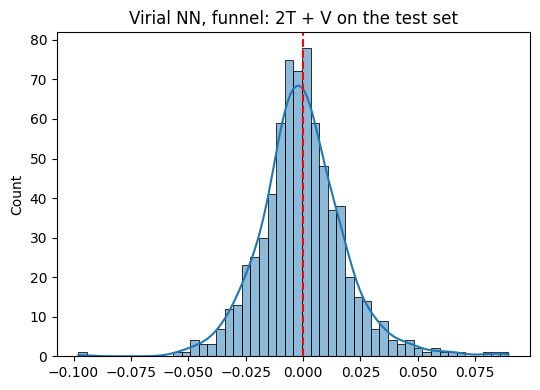

In [24]:
fig, axes = plt.subplots(1, len(pinn), figsize=(5.5 * len(pinn), 4), squeeze=False)
for ax, (name, m) in zip(axes[0], pinn.items()):
    _, T, V = m.predict(X_test_scaled, verbose=0)
    sns.histplot((2 * T + V).ravel(), bins=50, kde=True, ax=ax)
    ax.axvline(0, color="r", ls="--"); ax.set_title(f"Virial NN, {name}: 2T + V on the test set")
plt.tight_layout(); plt.show()

**Reading the result.** The virial network's error (MAE 13.9 kcal/mol, RMSE 18.3) is 1.2 kcal/mol higher than the plain network's (12.7, RMSE 16.6). That is about the size of the run-to-run variation of these networks, so a single run cannot call it a loss. But across three runs of this comparison the virial network never came out ahead: it was worse by 1.5, 0.2 and now 1.3 kcal/mol. It also consistently reaches its best validation loss much earlier (epoch 50 here, against 280) without ending any better. The residuals 2T + V cluster near zero, which looks like the constraint is being met; the next section shows why that is not evidence of physics.

## 1.5 Why the penalty cannot help

Both auxiliary heads read the same hidden vector **h**:

$$T = \mathbf w_T\!\cdot\!\mathbf h + b_T,\qquad V = \mathbf w_V\!\cdot\!\mathbf h + b_V \;\;\Rightarrow\;\; 2T+V = (2\mathbf w_T + \mathbf w_V)\cdot\mathbf h + (2b_T + b_V)$$

QM7 has no labels for ⟨T⟩ or ⟨V⟩, so nothing ties them to real values. Setting $\mathbf w_V = -2\mathbf w_T$ and $b_V = -2b_T$ makes the residual vanish **for every molecule, whatever h contains**, while ⟨T⟩ still varies and the energy head is untouched. The penalty can therefore be met by the output layer alone, without the network learning anything about the molecules. The cell below demonstrates this numerically on the trained network. The small residuals in the histogram above are a property of how the loss is built, not evidence of physical consistency.

Tying the heads to the energy does not help either: with E = T + V, the heads can simply copy the energy head (⟨T⟩ = −E, ⟨V⟩ = 2E) and satisfy every identity. Without labels for the quantities it constrains, the term can at most act as a regularizer.

In [25]:
def physics_gradient_share(m, n=512):
    xb, yb = tf.constant(X_train_scaled[:n], tf.float32), tf.constant(y_train[:n], tf.float32)
    hidden = [v for l in m.hidden_layers for v in l.trainable_variables]
    with tf.GradientTape(persistent=True) as tape:
        _, dl, pl = m.loss_terms(xb, yb, False)
        weighted_pl = m.lambda_phys * pl          # computed inside the tape so it can be differentiated
    g_data = tf.linalg.global_norm(tape.gradient(dl, hidden)).numpy()
    g_phys = tf.linalg.global_norm(tape.gradient(weighted_pl, hidden)).numpy()
    return g_data, g_phys

for name, m in pinn.items():
    X = tf.constant(X_test_scaled, tf.float32)
    p, T, V = [t.numpy() for t in m(X)]
    H = m.hidden_features(X).numpy()
    wT, bT = m.T_head.kernel.numpy(), m.T_head.bias.numpy()
    V_constructed = H @ (-2 * wT) + (-2 * bT)             # V head replaced by -2 x T head
    g_data, g_phys = physics_gradient_share(m)
    print(f"Virial NN, {name}")
    print(f"  as trained:              RMS(2T + V) = {np.sqrt(np.mean((2*T + V)**2)):.2e}   spread of T = {T.std():.3f}")
    print(f"  with V head := -2 T head: RMS(2T + V) = {np.sqrt(np.mean((2*T + V_constructed)**2)):.2e}   "
          f"spread of T = {T.std():.3f}   (classifier untouched)")
    print(f"  gradient into hidden layers: data {g_data:.2e}, physics {g_phys:.2e} (physics/data = {g_phys/g_data:.1e})\n")

Virial NN, funnel
  as trained:              RMS(2T + V) = 1.89e-02   spread of T = 0.303
  with V head := -2 T head: RMS(2T + V) = 6.55e-08   spread of T = 0.303   (classifier untouched)
  gradient into hidden layers: data 1.20e-01, physics 1.49e-03 (physics/data = 1.2e-02)



**Reading the check.** Replacing the trained ⟨V⟩ head with −2 times the ⟨T⟩ head drives the residual from 1.9 × 10⁻² to 6.6 × 10⁻⁸, float32 rounding, i.e. exactly zero for every test molecule. ⟨T⟩ keeps varying across molecules (standard deviation 0.33), and the energy head is untouched (the printout says "classifier", a leftover label). The virial penalty can therefore be met perfectly by the output layer alone, so the small residuals in Section 1.4 are **not** evidence of physical consistency.

At the end of training, the physics term's gradient into the hidden layers is about 1% of the data gradient, so it still pushes on the representation. But all it can push towards is keeping $(2\mathbf w_T + \mathbf w_V)\cdot\mathbf h$ constant, a geometric property of the representation, not a physical one. Without labels for ⟨T⟩ or ⟨V⟩, the term can at most act as a regularizer, and here it did not even help as one.

## 1.6 Conclusions and outlook

* **The data was the first bottleneck.** DeepChem's QM7 loader delivered features and labels that did not match, capping every model near 60% accuracy. A composition-only sanity check exposed it; the original `qm7.mat` passes the same check with R² = 0.992.
* **On correct data, classification is trivial.** Composition alone reaches 97.4%, and the remaining errors sit a median of 5.8 kcal/mol from the threshold, so the study moved to regression.
* **Training settings and representation matter more than architecture.** Dropout and a fixed learning rate, harmless for classification, left the regression network worse than a linear model on atom counts (MAE 21.5 kcal/mol in the reference run, 20–33 across runs). Removing them gave 15.2, and sorting the Coulomb matrices gave 12.7, about 2.7 kcal/mol below the best atom-count model. A random forest on sorted matrices remains the best model here (10.5 kcal/mol).
* **The virial penalty gives no measurable gain**, and it cannot: two unlabelled heads can always satisfy it without learning physics. In four runs the virial network never beat the plain one (0.2–1.5 kcal/mol worse). A multi-seed comparison would put a confidence interval on that.

**Two requirements for a useful physics term follow:** it must be **anchored to data**, comparing predictions with something measured, and it must be **impossible to satisfy trivially**, with no shortcut that drives it to zero without learning the physics.

**Next step: QM9.** The energy loss of *Energy Loss Functions for Physical Systems* (NeurIPS 2025, [arXiv:2511.02087](https://arxiv.org/abs/2511.02087)) meets both requirements. It charges a predicted geometry the energy of springs on interatomic distances needed to deform it into the reference, so it is anchored to the true distances and is zero only for the correct geometry. It needs a model whose output is a geometry, which makes QM9 geometry relaxation with an equivariant graph network the natural follow-up. Physics-motivated spring constants, such as the Coulomb curvature $k_{ij} \propto Z_iZ_j/d_{ij}^3$ that links back to the QM7 features, are a variation worth testing there.